# KPIs: did the average Filipino's life get better, 1960-2025?

Five KPIs in two tiers. The official tier is what the national accounts say.
The lived tier tests whether that gain reached people, who shared it, and what
it cost.

| Tier | KPI | Question it answers |
|---|---|---|
| Official | 1. Real GDP per capita | Did the country produce more per person? |
| Lived | 2. Infant mortality | Did more babies survive their first year? |
| Lived | 3. Gini index | Did the gain spread out or pile up at the top? |
| Lived | 4. Remittance dependence | How much of national income rests on someone working abroad? |
| Lived | 5. Kilos of rice per day's minimum wage | What does a day of work buy? |

**Why five.** The processed data holds more than a dozen candidate measures.
These five keep one per question: income, survival, distribution, dependence, and
what a day's work buys. One official number anchors the set; four lived numbers
test it.

**Why Gini and remittances sit in the lived tier.** Neither measures a
person's life directly. Both qualify the official number. Gini says whether
the national average describes the typical household. Remittances say how much
of national income depends on a family member living abroad. Both describe how
the gain reached households, which is the lived question.

**How to read "better".** Each KPI has a direction: higher is better for GDP
per capita and kilos of rice; lower is better for infant mortality, Gini, and
remittance share. Every KPI is read over two windows:

- **Long run:** first observed year against the latest observed year.
- **Recent:** the latest year against the last reading at least 10 years
  earlier.

If a move is under 5% of the window's starting value, it counts as flat.
**Improved** means better on both windows, **worsened** means worse on both,
and anything else is **mixed**.

The charts show how each KPI moved over time. They do not show what caused the
moves. Sources: `data/processed/indicators.csv` (World Bank API) for KPIs 1-4
and `data/processed/wage_rice.csv` (NWPC wage orders, PSA rice prices) for
KPI 5. Nothing is imputed. See `docs/SCHEMA.md`, `docs/CLEANING-NOTES.md` and
`docs/WAGE-RICE.md`.

In [1]:
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
from pathlib import Path

ROOT = Path.cwd().parent
FIGS = ROOT / "output" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(ROOT / "data" / "processed" / "indicators.csv", index_col="year")
wage_rice = pd.read_csv(ROOT / "data" / "processed" / "wage_rice.csv", index_col="year")
df = df.join(wage_rice["rice_kg_per_day_wage"])

BLUE, ORANGE, AQUA, YELLOW, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
SURFACE, GRID, MUTED, INK = "#fcfcfb", "#e1e0d9", "#898781", "#26251f"

pio.templates["dep"] = go.layout.Template(
    layout=dict(
        paper_bgcolor=SURFACE,
        plot_bgcolor=SURFACE,
        font=dict(family="Helvetica Neue, Helvetica, Arial", size=13, color=INK),
        title=dict(font=dict(size=18, color=INK), x=0, xanchor="left", y=0.94),
        margin=dict(l=64, r=36, t=76, b=56),
        xaxis=dict(showgrid=False, showline=True, linecolor=GRID, linewidth=1,
                   ticks="outside", tickcolor=GRID, ticklen=4,
                   tickfont=dict(color=MUTED, size=12),
                   title=dict(font=dict(color=MUTED, size=12))),
        yaxis=dict(showgrid=True, gridcolor=GRID, gridwidth=1, griddash="solid",
                   zeroline=False, showline=False,
                   tickfont=dict(color=MUTED, size=12),
                   title=dict(font=dict(color=MUTED, size=12))),
        showlegend=False,
        hovermode="x unified",
    )
)
pio.templates.default = "dep"
# Emit both the interactive figure and a static PNG so the saved notebook
# renders anywhere, including plain GitHub.
pio.renderers.default = "plotly_mimetype+png"

def save(fig, name):
    fig.write_image(FIGS / f"kpi-{name}.png", width=1000, height=560, scale=2)
    return fig

print(f"{len(df)} rows, {df.index.min()}-{df.index.max()}")

66 rows, 1960-2025


## Calculation rules

One set of rules for every KPI, so the verdicts are comparable. `change()`
measures one window. `windows()` picks the long-run and recent windows from the
years a series actually has. `direction()` and `verdict()` apply the rules
above. A KPI whose source changes method partway can set `since`, the first
year its readings compare like with like; its windows start there.

In [2]:
FLAT_PCT = 5       # a move smaller than this, as % of the start value, is flat
RECENT_YEARS = 10  # recent window: latest year vs last reading >= 10 years earlier

def change(s, start, end):
    a, b = s[start], s[end]
    return dict(start=start, start_value=a, end=end, end_value=b,
                change=b - a,
                change_pct=(b / a - 1) * 100,
                annual_pct=((b / a) ** (1 / (end - start)) - 1) * 100)

def windows(s):
    s = s.dropna()
    latest = s.index.max()
    recent_start = s.index[s.index <= latest - RECENT_YEARS].max()
    return change(s, s.index.min(), latest), change(s, recent_start, latest)

def direction(change_pct, better):
    signed = change_pct if better == "higher" else -change_pct
    if signed > FLAT_PCT:
        return "better"
    if signed < -FLAT_PCT:
        return "worse"
    return "flat"

def verdict(long_dir, recent_dir):
    if long_dir == recent_dir == "better":
        return "improved"
    if long_dir == recent_dir == "worse":
        return "worsened"
    return "mixed"

def shade_recent(fig, recent):
    fig.add_vrect(x0=recent["start"], x1=recent["end"], fillcolor=GRID,
                  opacity=0.45, line_width=0, layer="below",
                  annotation_text="recent window", annotation_position="top left",
                  annotation_font=dict(color=MUTED, size=12))

def show_windows(long_run, recent):
    return pd.DataFrame([long_run, recent], index=["long run", "recent"]).round(2)

## Definitions

Coverage is counted from the data. KPI 5 comes from `wage_rice.csv`, joined
on `year`.

In [3]:
KPIS = [
    dict(kpi="1. Real GDP per capita", tier="Official", column="gdp_per_capita_const",
         source="indicators.csv", better="higher", unit="constant 2015 US$",
         formula="GDP in constant 2015 US$ / mid-year population (World Bank NY.GDP.PCAP.KD)",
         limits="National average: says nothing about who received it. In US dollars, "
                "so it carries exchange-rate effects."),
    dict(kpi="2. Infant mortality", tier="Lived", column="infant_mortality",
         source="indicators.csv", better="lower", unit="deaths per 1,000 live births",
         formula="Deaths before age 1 per 1,000 live births in the same year "
                 "(SP.DYN.IMRT.IN)",
         limits="UN inter-agency modelled estimate, published on a lag; no 2025 value. "
                "National rate only, no regional split."),
    dict(kpi="3. Gini index", tier="Lived", column="gini",
         source="indicators.csv", better="lower", unit="index, 0-100", since=2000,
         formula="Gini coefficient x 100 (SI.POV.GINI), from the PSA Family Income and "
                 "Expenditure Survey: household consumption 1985-1997, household "
                 "income 2000-2023 (World Bank PIP)",
         limits="14 survey readings, none before 1985; gaps are unmeasured years. "
                "Income and consumption Ginis do not compare, so the verdict uses "
                "2000-2023 only. Measures spread, not level."),
    dict(kpi="4. Remittance dependence", tier="Lived", column="remittances",
         source="indicators.csv", better="lower", unit="% of GDP",
         formula="Personal remittances received / GDP x 100 (BX.TRF.PWKR.DT.GD.ZS)",
         limits="A share: it falls when GDP grows faster than remittances, even if "
                "families receive more. Lower-is-better is a judgment: less of the "
                "country's income resting on work abroad."),
    dict(kpi="5. Kilos of rice per day's minimum wage", tier="Lived",
         column="rice_kg_per_day_wage", source="wage_rice.csv", better="higher",
         unit="kg of regular-milled rice",
         formula="ncr_min_wage_daily / rice_regular_milled_ncr: day-weighted annual "
                 "average NCR non-agriculture minimum wage incl. COLA (NWPC wage orders) "
                 "/ PSA annual average NCR retail price of regular-milled rice per kg",
         limits="NCR minimum-wage earners only; the minimum is a legal floor and "
                "informal workers can earn below it. Regular-milled rice only. One food "
                "item, not the cost of living. PSA rice series changes in 2018."),
]

def kpi_series(k):
    """The KPI's readings from the year its verdict starts."""
    return df[k["column"]].loc[k.get("since"):].dropna()

def coverage(col):
    s = df[col].dropna()
    return f"{s.index.min()}-{s.index.max()}, {len(s)} years"

defs = pd.DataFrame([
    {"KPI": k["kpi"], "Tier": k["tier"], "Formula / calculation": k["formula"],
     "Source column": f"{k['source']}: {k['column']}", "Unit": k["unit"],
     "Coverage": coverage(k["column"]), "Better when": k["better"],
     "Known limits": k["limits"]}
    for k in KPIS
])

defs.style.hide(axis="index").set_properties(**{"text-align": "left"})

KPI,Tier,Formula / calculation,Source column,Unit,Coverage,Better when,Known limits
1. Real GDP per capita,Official,GDP in constant 2015 US$ / mid-year population (World Bank NY.GDP.PCAP.KD),indicators.csv: gdp_per_capita_const,constant 2015 US$,"1960-2025, 66 years",higher,"National average: says nothing about who received it. In US dollars, so it carries exchange-rate effects."
2. Infant mortality,Lived,"Deaths before age 1 per 1,000 live births in the same year (SP.DYN.IMRT.IN)",indicators.csv: infant_mortality,"deaths per 1,000 live births","1960-2024, 65 years",lower,"UN inter-agency modelled estimate, published on a lag; no 2025 value. National rate only, no regional split."
3. Gini index,Lived,"Gini coefficient x 100 (SI.POV.GINI), from the PSA Family Income and Expenditure Survey: household consumption 1985-1997, household income 2000-2023 (World Bank PIP)",indicators.csv: gini,"index, 0-100","1985-2023, 14 years",lower,"14 survey readings, none before 1985; gaps are unmeasured years. Income and consumption Ginis do not compare, so the verdict uses 2000-2023 only. Measures spread, not level."
4. Remittance dependence,Lived,Personal remittances received / GDP x 100 (BX.TRF.PWKR.DT.GD.ZS),indicators.csv: remittances,% of GDP,"1977-2025, 49 years",lower,"A share: it falls when GDP grows faster than remittances, even if families receive more. Lower-is-better is a judgment: less of the country's income resting on work abroad."
5. Kilos of rice per day's minimum wage,Lived,ncr_min_wage_daily / rice_regular_milled_ncr: day-weighted annual average NCR non-agriculture minimum wage incl. COLA (NWPC wage orders) / PSA annual average NCR retail price of regular-milled rice per kg,wage_rice.csv: rice_kg_per_day_wage,kg of regular-milled rice,"1990-2025, 36 years",higher,"NCR minimum-wage earners only; the minimum is a legal floor and informal workers can earn below it. Regular-milled rice only. One food item, not the cost of living. PSA rice series changes in 2018."


## 1. Real GDP per capita (official tier)

In [4]:
gdp = df["gdp_per_capita_const"].dropna()
gdp_long, gdp_recent = windows(gdp)

# The pre-1990 peak and the first later year that beat it.
gdp_peak = gdp.loc[:1990].idxmax()
gdp_regained = gdp[(gdp.index > gdp_peak) & (gdp > gdp[gdp_peak])].index.min()
gdp_ratio = gdp_long["end_value"] / gdp_long["start_value"]

print(f"{gdp_ratio:.2f}x since {gdp_long['start']}; "
      f"{gdp_peak} peak ${gdp[gdp_peak]:,.0f} regained in {gdp_regained}")
show_windows(gdp_long, gdp_recent)

3.62x since 1960; 1982 peak $1,898 regained in 2004


,start,start_value,end,end_value,change,change_pct,annual_pct
long run,1960,1123.78,2025,4065.89,2942.10,261.80,2.0
recent,2015,2909.86,2025,4065.89,1156.03,39.73,3.4


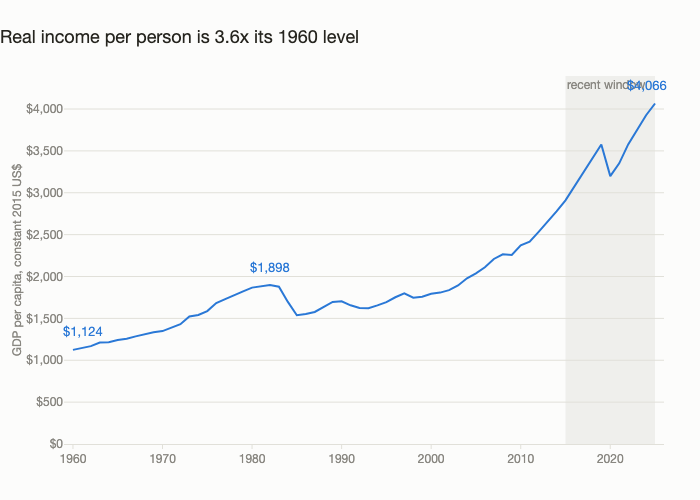

In [5]:
fig = go.Figure()
fig.add_trace(go.Scatter(
    x=gdp.index, y=gdp.values, mode="lines", line=dict(color=BLUE, width=2),
    hovertemplate="%{x}: $%{y:,.0f}<extra></extra>"))
shade_recent(fig, gdp_recent)

for yr, dx in [(gdp_long["start"], 10), (gdp_peak, 0), (gdp_long["end"], -8)]:
    fig.add_annotation(x=yr, y=gdp[yr], text=f"${gdp[yr]:,.0f}", showarrow=False,
                       yshift=18, xshift=dx, font=dict(color=BLUE, size=13))

fig.update_layout(
    title=f"Real income per person is {gdp_ratio:.1f}x its {gdp_long['start']} level",
    yaxis_title="GDP per capita, constant 2015 US$", xaxis_title=None,
    yaxis_tickprefix="$", yaxis_tickformat=",", yaxis_rangemode="tozero",
    xaxis_range=[1959, 2026])
save(fig, "01-gdp-per-capita")
fig.show()

### Observation
Real GDP per capita rose from $1,124 in 1960 to $4,066 in 2025, 3.6 times the
start, or 2.0% a year compounded. The last ten years ran faster: 3.4% a year
from $2,910 in 2015, including the 2020 drop. The long run hides a stall: the
1982 level of $1,898 was not beaten again until 2004.

## 2. Infant mortality (lived tier)

In [6]:
imr = df["infant_mortality"].dropna()
imr_long, imr_recent = windows(imr)

# How much of the total fall was already done by 2000.
imr_share_by_2000 = (imr.iloc[0] - imr[2000]) / (imr.iloc[0] - imr.iloc[-1]) * 100
imr_floor = imr.loc[:2015].idxmin()           # lowest rate before the recent rise
imr_bump = imr.loc[imr_floor:2021].idxmax()   # highest point after it

print(f"{imr_share_by_2000:.0f}% of the fall done by 2000; "
      f"{imr[imr_floor]} in {imr_floor} rose to {imr[imr_bump]} in {imr_bump}")
show_windows(imr_long, imr_recent)

86% of the fall done by 2000; 22.1 in 2014 rose to 22.7 in 2020


,start,start_value,end,end_value,change,change_pct,annual_pct
long run,1960,62.3,2024,21.7,-40.6,-65.17,-1.63
recent,2014,22.1,2024,21.7,-0.4,-1.81,-0.18


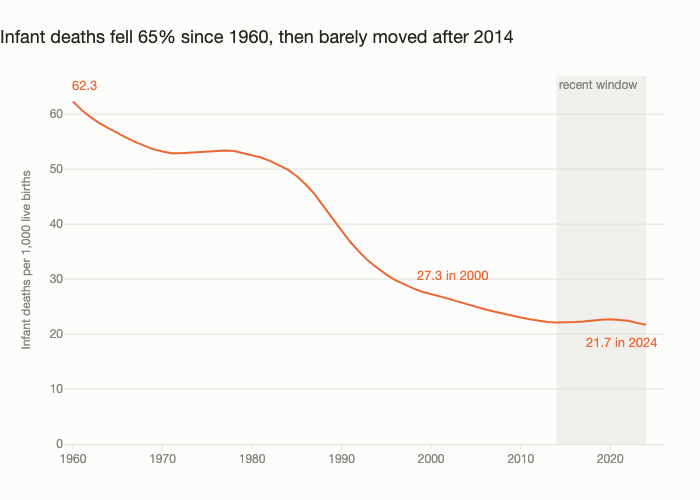

In [7]:
fig = go.Figure()
fig.add_trace(go.Scatter(
    x=imr.index, y=imr.values, mode="lines", line=dict(color=ORANGE, width=2),
    hovertemplate="%{x}: %{y:.1f} per 1,000<extra></extra>"))
shade_recent(fig, imr_recent)

fig.add_annotation(x=imr_long["start"], y=imr[imr_long["start"]],
                   text=f"{imr[imr_long['start']]:.1f}", showarrow=False,
                   yshift=16, xshift=12, font=dict(color=ORANGE, size=13))
fig.add_annotation(x=2000, y=imr[2000], text=f"{imr[2000]:.1f} in 2000",
                   showarrow=False, yshift=18, xshift=22, font=dict(color=ORANGE, size=13))
fig.add_annotation(x=imr_long["end"], y=imr[imr_long["end"]],
                   text=f"{imr[imr_long['end']]:.1f} in {imr_long['end']}",
                   showarrow=False, yshift=-18, xshift=-24, font=dict(color=ORANGE, size=13))

fig.update_layout(
    title=f"Infant deaths fell {-imr_long['change_pct']:.0f}% since "
          f"{imr_long['start']}, then barely moved after {imr_recent['start']}",
    yaxis_title="Infant deaths per 1,000 live births", xaxis_title=None,
    yaxis_rangemode="tozero", xaxis_range=[1959, 2026])
save(fig, "02-infant-mortality")
fig.show()

### Observation
Infant mortality fell from 62.3 deaths per 1,000 live births in 1960 to 21.7 in
2024, a 65.2% drop. 86% of that fall was done by 2000, when the rate was 27.3.
Since 2014 it moved 0.4 deaths, from 22.1 to 21.7, after rising from 22.1 in
2014 to 22.7 in 2020.

## 3. Gini index (lived tier)

In [8]:
gini = df["gini"].dropna()
GINI_SINCE = next(k["since"] for k in KPIS if k["column"] == "gini")
gini_consumption, gini_income = gini.loc[:GINI_SINCE - 1], gini.loc[GINI_SINCE:]
gini_long, gini_recent = windows(gini_income)
gini_peak = gini.idxmax()

print(f"{len(gini)} readings: {len(gini_consumption)} consumption "
      f"({gini_consumption.index.min()}-{gini_consumption.index.max()}), "
      f"{len(gini_income)} income ({gini_income.index.min()}-{gini_income.index.max()}); "
      f"peak {gini[gini_peak]} in {gini_peak}; "
      f"income readings at 46 or above: {gini_income[gini_income >= 46].index.tolist()}")
show_windows(gini_long, gini_recent)

14 readings: 5 consumption (1985-1997), 9 income (2000-2023); peak 47.7 in 2000; income readings at 46 or above: [2000, 2003, 2006, 2009, 2012]


,start,start_value,end,end_value,change,change_pct,annual_pct
long run,2000,47.7,2023,39.3,-8.4,-17.61,-0.84
recent,2012,46.5,2023,39.3,-7.2,-15.48,-1.52


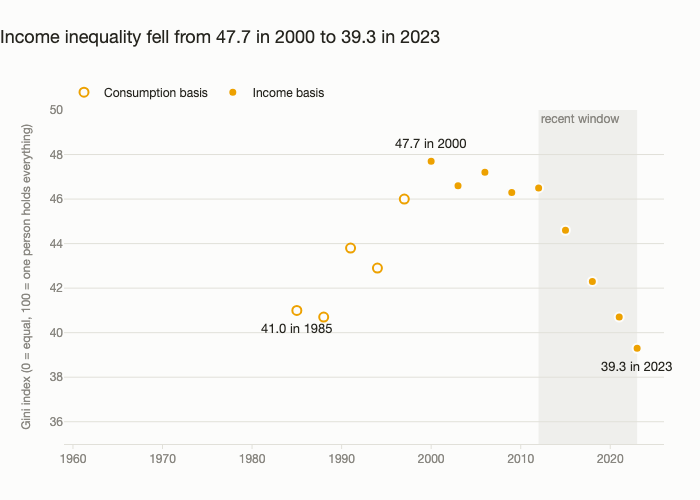

In [9]:
fig = go.Figure()
# Markers only: 14 survey readings, and a line between them would draw years
# nobody measured. Hollow markers are the consumption-based readings.
fig.add_trace(go.Scatter(
    x=gini_consumption.index, y=gini_consumption.values, mode="markers",
    name="Consumption basis", marker=dict(color=SURFACE, size=9, line=dict(color=YELLOW, width=2)),
    hovertemplate="%{x}: %{y:.1f} (consumption)<extra></extra>"))
fig.add_trace(go.Scatter(
    x=gini_income.index, y=gini_income.values, mode="markers",
    name="Income basis", marker=dict(color=YELLOW, size=9, line=dict(color=SURFACE, width=2)),
    hovertemplate="%{x}: %{y:.1f} (income)<extra></extra>"))
shade_recent(fig, gini_recent)

for yr, dy in [(gini.index.min(), -18), (gini_long["start"], 18), (gini_long["end"], -18)]:
    fig.add_annotation(x=yr, y=gini[yr], text=f"{gini[yr]:.1f} in {yr}",
                       showarrow=False, yshift=dy, font=dict(color=INK, size=13))

fig.update_layout(
    title=f"Income inequality fell from {gini_long['start_value']:.1f} in "
          f"{gini_long['start']} to {gini_long['end_value']:.1f} in {gini_long['end']}",
    yaxis_title="Gini index (0 = equal, 100 = one person holds everything)",
    xaxis_title=None, yaxis_range=[35, 50], xaxis_range=[1959, 2026],
    showlegend=True, hovermode="closest",
    legend=dict(orientation="h", x=0, y=1.01, xanchor="left", yanchor="bottom",
                font=dict(color=INK, size=12)),
    margin=dict(t=110))
save(fig, "03-gini")
fig.show()

### Observation
The World Bank series changes measure in 2000. The five readings from 1985 to
1997 measure how evenly households consume; the nine from 2000 to 2023
measure how evenly they earn. Income is spread less evenly than consumption,
so the 1985-1997 readings are not comparable with 2000 onward, and the gap
between 46.0 in 1997 and 47.7 in 2000 is not a measured change. The verdict
uses the income readings only. On that basis inequality sat at 46
or above from 2000 to 2012, then fell at every survey after 2012, to 39.3 in
2023: 8.4 points below 2000 and 7.2 below 2012. PIP also flags changes in survey
method in 2003 and 2015, so even the income readings are not strictly
comparable across those years. The 1985 reading of 41.0 measures
consumption, so this notebook makes no 1985-to-2023 claim. Fourteen
survey readings carry the chart, and the space between markers is years
nobody measured.

## 4. Remittance dependence (lived tier)

In [10]:
rem = df["remittances"].dropna()
rem_long, rem_recent = windows(rem)
rem_peak = rem.idxmax()
rem_ratio = rem_long["end_value"] / rem_long["start_value"]
rem_ten_plus = rem[rem >= 10].index

print(f"{rem_ratio:.1f}x the {rem_long['start']} share; peak {rem[rem_peak]:.1f}% "
      f"in {rem_peak}; 10% or more in {rem_ten_plus.min()}-{rem_ten_plus.max()} "
      f"({len(rem_ten_plus)} years)")
show_windows(rem_long, rem_recent)

5.6x the 1977 share; peak 12.8% in 2005; 10% or more in 2001-2010 (10 years)


,start,start_value,end,end_value,change,change_pct,annual_pct
long run,1977,1.52,2025,8.53,7.01,460.86,3.66
recent,2015,9.72,2025,8.53,-1.19,-12.26,-1.30


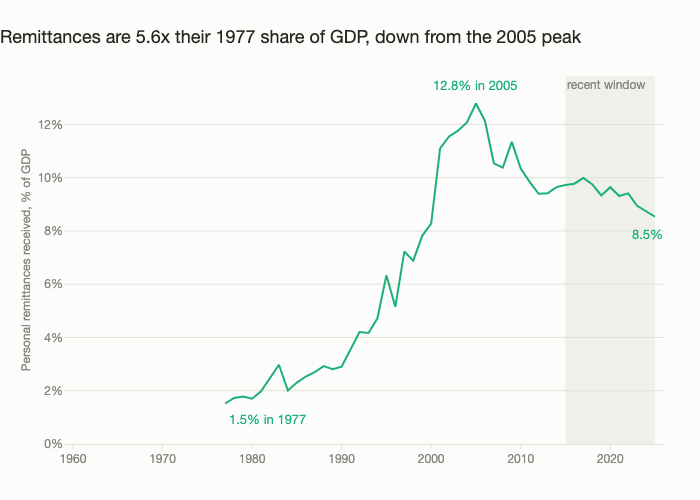

In [11]:
fig = go.Figure()
fig.add_trace(go.Scatter(
    x=rem.index, y=rem.values, mode="lines", line=dict(color=AQUA, width=2),
    hovertemplate="%{x}: %{y:.1f}% of GDP<extra></extra>"))
shade_recent(fig, rem_recent)

fig.add_annotation(x=rem_long["start"], y=rem[rem_long["start"]],
                   text=f"{rem[rem_long['start']]:.1f}% in {rem_long['start']}",
                   showarrow=False, yshift=-16, xshift=42, font=dict(color=AQUA, size=13))
fig.add_annotation(x=rem_peak, y=rem[rem_peak], text=f"{rem[rem_peak]:.1f}% in {rem_peak}",
                   showarrow=False, yshift=18, font=dict(color=AQUA, size=13))
fig.add_annotation(x=rem_long["end"], y=rem[rem_long["end"]],
                   text=f"{rem[rem_long['end']]:.1f}%", showarrow=False,
                   yshift=-18, xshift=-8, font=dict(color=AQUA, size=13))

fig.update_layout(
    title=f"Remittances are {rem_ratio:.1f}x their {rem_long['start']} share of GDP, "
          f"down from the {rem_peak} peak",
    yaxis_title="Personal remittances received, % of GDP", xaxis_title=None,
    yaxis_ticksuffix="%", yaxis_rangemode="tozero", xaxis_range=[1959, 2026])
save(fig, "04-remittances")
fig.show()

### Observation
Remittances were 1.5% of GDP in 1977 and 8.5% in 2025, 5.6 times the starting
share. The share sat at 10% or more every year from 2001 to 2010 and peaked at
12.8% in 2005. Since 2015 it fell from 9.7% to 8.5%; this series cannot say
whether that came from less money sent home or from GDP growing faster.

## 5. Kilos of rice per day's minimum wage (lived tier)

What one day of the Metro Manila minimum wage buys in regular-milled rice.
The wage is the day-weighted annual average of the non-agriculture rate,
COLA included; the price is PSA's annual average for NCR. The series covers
NCR minimum-wage earners and regular-milled rice only. Method:
`docs/WAGE-RICE.md`.

In [12]:
rice = df["rice_kg_per_day_wage"].dropna()
rice_long, rice_recent = windows(rice)
rice_low, rice_high = rice.idxmin(), rice.idxmax()
rice_pre_2008 = rice.loc[2002:2007]          # the run before the 2008 rice-price jump
rice_2008_2024 = rice.loc[2008:2024]
rice_price = wage_rice["rice_regular_milled_ncr"]
wage = wage_rice["ncr_min_wage_daily"]

print(f"low {rice[rice_low]:.2f} kg in {rice_low}; high {rice[rice_high]:.2f} kg in {rice_high}; "
      f"2002-2007 range {rice_pre_2008.min():.1f}-{rice_pre_2008.max():.1f}; "
      f"2008-2024 best {rice_2008_2024.max():.1f} in {rice_2008_2024.idxmax()}")
print(f"rice per kg 2007 {rice_price[2007]:.2f} -> 2008 {rice_price[2008]:.2f}; "
      f"2024 {rice_price[2024]:.2f} -> 2025 {rice_price[2025]:.2f}; wage 2025 {wage[2025]:.2f}")
show_windows(rice_long, rice_recent)

low 9.09 kg in 1996; high 16.22 kg in 2025; 2002-2007 range 15.1-15.8; 2008-2024 best 14.6 in 2012
rice per kg 2007 22.45 -> 2008 30.67; 2024 45.28 -> 2025 41.17; wage 2025 667.88


,start,start_value,end,end_value,change,change_pct,annual_pct
long run,1990,10.37,2025,16.22,5.86,56.50,1.29
recent,2015,13.01,2025,16.22,3.22,24.73,2.23


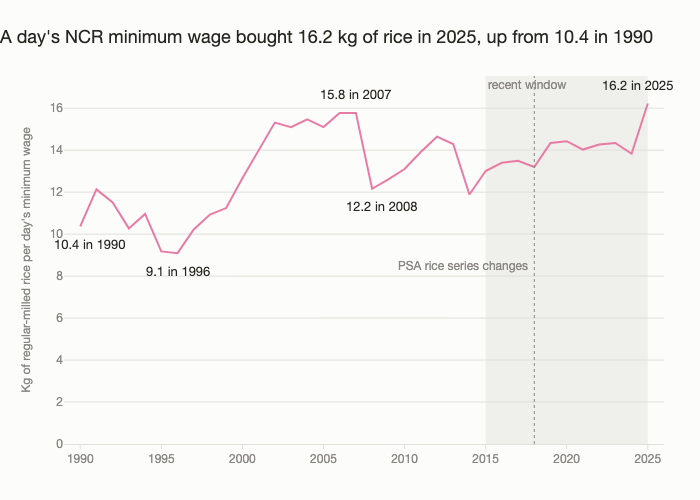

In [13]:
fig = go.Figure()
fig.add_trace(go.Scatter(
    x=rice.index, y=rice.values, mode="lines", line=dict(color=MAGENTA, width=2),
    hovertemplate="%{x}: %{y:.1f} kg<extra></extra>"))
shade_recent(fig, rice_recent)
fig.add_vline(x=2018, line_color=MUTED, line_width=1, line_dash="dot")
fig.add_annotation(x=2018, y=8.5, text="PSA rice series changes", showarrow=False,
                   xanchor="right", xshift=-4, font=dict(color=MUTED, size=12))

for yr, dy, dx in [(rice_long["start"], -18, 10), (rice_low, -18, 0), (2007, 18, 0),
                   (2008, -18, 10), (rice_high, 18, -10)]:
    fig.add_annotation(x=yr, y=rice[yr], text=f"{rice[yr]:.1f} in {yr}", showarrow=False,
                       yshift=dy, xshift=dx, font=dict(color=INK, size=13))

fig.update_layout(
    title=f"A day's NCR minimum wage bought {rice[rice_long['end']]:.1f} kg of rice in "
          f"{rice_long['end']}, up from {rice[rice_long['start']]:.1f} in {rice_long['start']}",
    yaxis_title="Kg of regular-milled rice per day's minimum wage", xaxis_title=None,
    yaxis_rangemode="tozero", xaxis_range=[1989, 2026])
save(fig, "05-rice-per-day-wage")
fig.show()

### Observation
A day of the NCR minimum wage bought 10.4 kg of regular-milled rice in 1990
and 16.2 kg in 2025, 56.5% more. The low was 9.09 kg in 1996. From there it
rose to 14.29 kg in 2013, but not steadily: a day's wage bought 15.1 to 15.8
kg every year from 2002 to 2007, then 12.2 kg in 2008, when rice went from
₱22.45 to ₱30.67 a kilo. In 2014 rice rose to ₱39.20 and the ratio fell to
11.89 kg. From 2015 to 2024 it held between 13.0 and 14.4 kg, ending at 13.83.
The 2025 figure of 16.22 kg follows a fall in the NCR rice price from ₱45.28
to ₱41.17 a kilo; the wage averaged ₱667.88.

The recent verdict is fragile. Its window starts in 2015 at 13.01 kg, one
year after the 2014 price spike, and ends at 2025, the single high year.
Ended at 2024 instead, the recent change would be +6.3%, just over the 5%
flat line.

This covers NCR minimum-wage earners and one grade of rice. It says nothing
about workers paid below the minimum, other regions, or the rest of the
grocery bill.

## Scorecard

Built from the same `windows()`, `direction()` and `verdict()` rules for every
KPI. Values are in each KPI's own unit (see Definitions). Baseline year is
where each verdict starts, so the long runs differ in length.

In [14]:
rows = []
for k in KPIS:
    long_run, recent = windows(kpi_series(k))
    long_dir = direction(long_run["change_pct"], k["better"])
    recent_dir = direction(recent["change_pct"], k["better"])
    rows.append({
        "KPI": k["kpi"], "Tier": k["tier"], "Better when": k["better"],
        "Baseline year": long_run["start"], "Baseline": long_run["start_value"],
        "Latest year": long_run["end"], "Latest": long_run["end_value"],
        "Change": long_run["change"], "Change %": long_run["change_pct"],
        "Long run": long_dir,
        "Recent from": recent["start"], "Recent change %": recent["change_pct"],
        "Recent": recent_dir,
        "Verdict": verdict(long_dir, recent_dir),
    })

scorecard = pd.DataFrame(rows)
scorecard.style.hide(axis="index").format(
    {"Baseline": "{:,.2f}", "Latest": "{:,.2f}", "Change": "{:+,.2f}",
     "Change %": "{:+.1f}%", "Recent change %": "{:+.1f}%"})

KPI,Tier,Better when,Baseline year,Baseline,Latest year,Latest,Change,Change %,Long run,Recent from,Recent change %,Recent,Verdict
1. Real GDP per capita,Official,higher,1960,"1,123.78",2025,"4,065.89","+2,942.10",+261.8%,better,2015,+39.7%,better,improved
2. Infant mortality,Lived,lower,1960,62.30,2024,21.70,-40.60,-65.2%,better,2014,-1.8%,flat,mixed
3. Gini index,Lived,lower,2000,47.70,2023,39.30,-8.40,-17.6%,better,2012,-15.5%,better,improved
4. Remittance dependence,Lived,lower,1977,1.52,2025,8.53,+7.01,+460.9%,worse,2015,-12.3%,better,mixed
5. Kilos of rice per day's minimum wage,Lived,higher,1990,10.37,2025,16.22,+5.86,+56.5%,better,2015,+24.7%,better,improved


### Observation
Three KPIs improved on both windows and two are mixed. Real GDP per capita is
up 261.8% since 1960 and 39.7% since 2015. Kilos of rice per day's minimum
wage is up 56.5% since 1990 and 24.7% since 2015. Gini, on the income basis,
fell 17.6% since 2000 and 15.5% since 2012. Infant mortality fell 65.2% over
the long run and moved 1.8% in the recent window, inside the flat band.
Remittance dependence rose 460.9% since 1977 and fell 12.3% since 2015.

The three improved KPIs start in 1960, 1990 and 2000, so "improved" covers
different spans. Rice's recent gain leans on 2025: against 2024 alone, the
recent window would read 13.8 kg, not 16.2.

## Number check

Every number quoted in the markdown above, recomputed. The notebook fails here
if the CSV changes and the text no longer matches.

In [15]:
quoted = {
    "GDP 1960": (f"${gdp[1960]:,.0f}", "$1,124"),
    "GDP 2025": (f"${gdp[2025]:,.0f}", "$4,066"),
    "GDP ratio": (f"{gdp_ratio:.1f}", "3.6"),
    "GDP annual, long": (f"{gdp_long['annual_pct']:.1f}", "2.0"),
    "GDP annual, recent": (f"{gdp_recent['annual_pct']:.1f}", "3.4"),
    "GDP 2015": (f"${gdp[2015]:,.0f}", "$2,910"),
    "GDP pre-1990 peak": (f"{gdp_peak} ${gdp[gdp_peak]:,.0f}", "1982 $1,898"),
    "GDP regained": (str(gdp_regained), "2004"),
    "GDP change %, long": (f"{gdp_long['change_pct']:.1f}", "261.8"),
    "GDP change %, recent": (f"{gdp_recent['change_pct']:.1f}", "39.7"),
    "IMR 1960": (f"{imr[1960]:.1f}", "62.3"),
    "IMR 2024": (f"{imr[2024]:.1f}", "21.7"),
    "IMR change %, long": (f"{-imr_long['change_pct']:.1f}", "65.2"),
    "IMR share by 2000": (f"{imr_share_by_2000:.0f}", "86"),
    "IMR 2000": (f"{imr[2000]:.1f}", "27.3"),
    "IMR recent": (f"{imr_recent['start']} {imr_recent['start_value']:.1f} "
                   f"{-imr_recent['change']:.1f} {-imr_recent['change_pct']:.1f}",
                   "2014 22.1 0.4 1.8"),
    "IMR bump": (f"{imr_floor} {imr[imr_floor]:.1f} {imr_bump} {imr[imr_bump]:.1f}",
                 "2014 22.1 2020 22.7"),
    "Gini first": (f"{gini.index.min()} {gini.iloc[0]:.1f}", "1985 41.0"),
    "Gini basis split": (f"{len(gini_consumption)} {gini_consumption.index.min()}-"
                         f"{gini_consumption.index.max()} {len(gini_income)} "
                         f"{gini_income.index.min()}-{gini_income.index.max()}",
                         "5 1985-1997 9 2000-2023"),
    "Gini 1997 to 2000": (f"{gini[1997]:.1f} {gini[2000]:.1f}", "46.0 47.7"),
    "Gini latest": (f"{gini_long['end']} {gini_long['end_value']:.1f}", "2023 39.3"),
    "Gini change, long": (f"{gini_long['start']} {-gini_long['change']:.1f} "
                          f"{-gini_long['change_pct']:.1f}", "2000 8.4 17.6"),
    "Gini peak": (f"{gini_peak} {gini[gini_peak]:.1f}", "2000 47.7"),
    "Gini income >= 46": (" ".join(map(str, gini_income[gini_income >= 46].index)),
                          "2000 2003 2006 2009 2012"),
    "Gini falls after 2012": (str(gini.loc[2012:].is_monotonic_decreasing), "True"),
    "Gini recent": (f"{gini_recent['start']} {gini_recent['start_value']:.1f} "
                    f"{-gini_recent['change']:.1f} {-gini_recent['change_pct']:.1f}",
                    "2012 46.5 7.2 15.5"),
    "Gini readings": (str(len(gini)), "14"),
    "Rem first": (f"{rem_long['start']} {rem_long['start_value']:.1f}", "1977 1.5"),
    "Rem latest": (f"{rem_long['end']} {rem_long['end_value']:.1f}", "2025 8.5"),
    "Rem ratio": (f"{rem_ratio:.1f}", "5.6"),
    "Rem change %, long": (f"{rem_long['change_pct']:.1f}", "460.9"),
    "Rem 10%+ years": (f"{rem_ten_plus.min()}-{rem_ten_plus.max()} {len(rem_ten_plus)}",
                       "2001-2010 10"),
    "Rem peak": (f"{rem_peak} {rem[rem_peak]:.1f}", "2005 12.8"),
    "Rem recent": (f"{rem_recent['start']} {rem_recent['start_value']:.1f} "
                   f"{-rem_recent['change_pct']:.1f}", "2015 9.7 12.3"),
    "Rice 1990": (f"{rice[1990]:.1f}", "10.4"),
    "Rice 2025": (f"{rice[2025]:.1f}", "16.2"),
    "Rice change %, long": (f"{rice_long['change_pct']:.1f}", "56.5"),
    "Rice low": (f"{rice[rice_low]:.2f} {rice_low}", "9.09 1996"),
    "Rice high": (f"{rice[rice_high]:.2f} {rice_high}", "16.22 2025"),
    "Rice 2002-2007": (f"{rice_pre_2008.min():.1f} {rice_pre_2008.max():.1f}", "15.1 15.8"),
    "Rice price 2007-2008": (f"{rice_price[2007]:.2f} {rice_price[2008]:.2f}", "22.45 30.67"),
    "Rice 2008": (f"{rice[2008]:.1f}", "12.2"),
    "Rice 2008-2024 below 15": (str(rice_2008_2024.max() < 15), "True"),
    "Rice 2008-2024 best": (f"{rice_2008_2024.max():.1f} {rice_2008_2024.idxmax()}", "14.6 2012"),
    "Rice price 2024-2025": (f"{rice_price[2024]:.2f} {rice_price[2025]:.2f}", "45.28 41.17"),
    "Wage 2025": (f"{wage[2025]:.2f}", "667.88"),
    "Rice recent": (f"{rice_recent['start']} {rice_recent['change_pct']:.1f}", "2015 24.7"),
    "Rice 2024": (f"{rice[2024]:.1f} {rice[2024]:.2f}", "13.8 13.83"),
    "Rice 2013": (f"{rice[2013]:.2f}", "14.29"),
    "Rice 2014 spike": (f"{rice_price[2014]:.2f} {rice[2014]:.2f}", "39.20 11.89"),
    "Rice 2015-2024 range": (f"{rice.loc[2015:2024].min():.1f} {rice.loc[2015:2024].max():.1f}",
                             "13.0 14.4"),
    "Rice recent start": (f"{rice_recent['start_value']:.2f}", "13.01"),
    "Rice recent to 2024": (f"{(rice[2024] / rice_recent['start_value'] - 1) * 100:+.1f}", "+6.3"),
    "Verdicts": (" ".join(scorecard["Verdict"]), "improved mixed improved mixed improved"),
}
mismatched = {k: v for k, v in quoted.items() if v[0] != v[1]}
assert not mismatched, mismatched
print(f"{len(quoted)} quoted figures match the data")

54 quoted figures match the data
